# 🛰️ Bare Soil Segmentation — Sentinel-2 Punjab

**Pipeline Overview:**
```
Sentinel-2 GeoTIFF (10 bands)
        │
        ▼
   Parquet (.parquet)  ←── Ground Truth Labels (crop=1 / bare=2 / unannotated=0)
        │
        ├──── TRAIN: Patiala (all months)
        └──── TEST:  Amritsar (all months)   ← geographic holdout, zero leakage
               │
               ├──── Approach 1: Raw Bands (10-D) → MLP Classifier
               │
               ├──── Approach 2: Spectral MAE Encoder (10→32-D CLS) → MLP Classifier
               │
               ├──── Approach 3: 32-D Embeddings → Random Forest
               │
               ├──── Approach 4: Ablation — band importance / architecture
               │
               └──── Approach 5 (Final): SegFormer — full spatial context
```

**Evaluation strategy:** Train on Patiala → Test on Amritsar (different district, different fields).  
This eliminates spatial leakage that causes artificially perfect scores with random pixel splits.

**Classes:** `0` = Non-annotated | `1` = Crop | `2` = Bare Soil  
**Goal:** Binary — Crop (0) vs Bare (1)


---
## 0. Setup & Imports

In [ ]:
# ── Install deps (Colab / fresh env) ──────────────────────────
import subprocess, sys

def pip_install(*pkgs):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *pkgs], check=True)

pip_install('transformers', 'timm', 'joblib', 'scikit-learn', 'pyarrow', 'tqdm', 'matplotlib', 'seaborn')
print('✅ Dependencies ready')

✅ Dependencies ready


In [ ]:
import os, gc, time, joblib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import psutil
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    f1_score, classification_report, confusion_matrix,
    roc_auc_score, precision_recall_curve, average_precision_score
)
from sklearn.ensemble import RandomForestClassifier
from tqdm.auto import tqdm
warnings.filterwarnings('ignore')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SEED   = 42
print(f'Device: {DEVICE}')
print(f'PyTorch: {torch.__version__}')
print(f'RAM available: {psutil.virtual_memory().available/1e9:.1f} GB  '
      f'/ Total: {psutil.virtual_memory().total/1e9:.1f} GB')
if psutil.virtual_memory().available < 6e9:
    print('⚠️  WARNING: Less than 6GB RAM free — consider restarting runtime '
          'and running only this notebook (close other tabs).')
else:
    print('✅ RAM looks sufficient')

def set_seed(seed=42):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

set_seed(SEED)

Device: cpu
PyTorch: 2.10.0+cpu
RAM available: 10.5 GB  / Total: 13.6 GB
✅ RAM looks sufficient


---
## 1. Paths & Global Config

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ── ✏️  EDIT THESE PATHS ──────────────────────────────────────
BASE_DIR         = '/content/drive/MyDrive/ILGC-V/'   # <-- update

# Training district — Patiala May
TRAIN_PATHS = [
    f'{BASE_DIR}parquet/Patiala/Patiala_S2_May.parquet',
]

# Test district — Amritsar May (geographic holdout)
TEST_PATHS = [
    f'{BASE_DIR}parquet/Amritsar/Amritsar_S2_may.parquet',
]

# Pre-trained Spectral MAE assets
# NOTE: trained on a large multi-district balanced dataset (training_data_balanced.parquet)
# The checkpoint is stored in the Patiala folder but is NOT district-specific.
CKPT_PATH   = f'{BASE_DIR}stitched/Patiala/spectral_mae_ckpt_32.pt'
SCALER_PATH = f'{BASE_DIR}stitched/Patiala/spectral_scaler_32.joblib'

BAND_COLS      = ['B11','B12','B2','B3','B4','B5','B6','B7','B8','B8A']
LAMBDAS_NM     = [1610, 2190, 490, 560, 665, 705, 740, 783, 842, 865]
FWHM_NM        = [  90,  180,  65,  35,  30,  15,  15,  20, 115,  20]
NUM_BANDS      = len(BAND_COLS)

# SpectralMAE hyper-params — verified by inspecting checkpoint keys directly.
EMBED_DIM  = 32
ENC_DEPTH  = 6   # verified: checkpoint has encoder layers 0–5
ENC_HEADS  = 4
DEC_DIM    = 32
DEC_DEPTH  = 3   # verified: checkpoint has decoder layers 0–2
DEC_HEADS  = 4
FOURIER_FF = 16

# Classification
BATCH_SIZE     = 16384
EPOCHS_MLP     = 10
LR             = 1e-3
WEIGHT_DECAY   = 0.01
EARLY_PATIENCE = 3

# Memory safety
MAX_TRAIN_ROWS = 3_000_000
MAX_TEST_ROWS  = 1_000_000

# Class balancing
BALANCE_TRAIN  = True
BALANCE_N      = 200_000

print('Config ready ✅')
print(f'Band order: {BAND_COLS}')
print(f'Encoder depth: ENC={ENC_DEPTH}, DEC={DEC_DEPTH}')

Config ready ✅
Band order: ['B11', 'B12', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A']
Encoder depth: ENC=6, DEC=3


---
## 2. Data Loading & EDA

In [ ]:
def ram_gb():
    return psutil.virtual_memory().available / 1e9

def load_district(paths, name, max_annotated_rows=None):
    """
    Memory-safe district loader:
    - Reads only the columns we need (band cols + target + coords)
    - Drops unannotated rows (target==0) immediately — these are ~75% of data
    - Optionally caps rows to avoid OOM on Colab
    """
    needed_cols = BAND_COLS + ['target', 'longitude', 'latitude']
    dfs = []
    for p in paths:
        print(f'  Loading: {p}  (RAM free: {ram_gb():.1f} GB)')
        df = pd.read_parquet(p, columns=needed_cols)   # ← only needed columns
        df = df[df['target'] != 0].reset_index(drop=True)  # ← drop unannotated immediately
        print(f'  After dropping unannotated: {len(df):,} rows')
        dfs.append(df)
        gc.collect()
    df = pd.concat(dfs, ignore_index=True)
    del dfs; gc.collect()

    if max_annotated_rows and len(df) > max_annotated_rows:
        print(f'  Capping {len(df):,} → {max_annotated_rows:,} rows (stratified)')
        from sklearn.model_selection import train_test_split
        df, _ = train_test_split(df, train_size=max_annotated_rows,
                                  stratify=df['target'], random_state=42)
        df = df.reset_index(drop=True)
        gc.collect()

    label_map = {1: 'crop', 2: 'bare'}
    print(f'{name} final shape: {df.shape}  (RAM free: {ram_gb():.1f} GB)')
    print(df['target'].value_counts().rename(label_map))
    return df

print(f'RAM free before loading: {ram_gb():.1f} GB')
print('=== TRAIN DISTRICT — Patiala (June) ===')
df_train = load_district(TRAIN_PATHS, 'Patiala', max_annotated_rows=MAX_TRAIN_ROWS)
print()
print('=== TEST DISTRICT — Amritsar (April) ===')
df_test  = load_district(TEST_PATHS,  'Amritsar', max_annotated_rows=MAX_TEST_ROWS)
print(f'\nRAM free after loading: {ram_gb():.1f} GB')

RAM free before loading: 12.2 GB
=== TRAIN DISTRICT — Patiala (June) ===
  Loading: /content/drive/MyDrive/ILGC-V/parquet/Patiala/Patiala_S2_May.parquet  (RAM free: 12.2 GB)
  After dropping unannotated: 13,051,656 rows
  Capping 13,051,656 → 3,000,000 rows (stratified)
Patiala final shape: (3000000, 13)  (RAM free: 8.6 GB)
target
bare    1597830
crop    1402170
Name: count, dtype: int64

=== TEST DISTRICT — Amritsar (April) ===
  Loading: /content/drive/MyDrive/ILGC-V/parquet/Amritsar/Amritsar_S2_may.parquet  (RAM free: 9.1 GB)
  After dropping unannotated: 39,351,500 rows
  Capping 39,351,500 → 1,000,000 rows (stratified)
Amritsar final shape: (1000000, 13)  (RAM free: 5.8 GB)
target
bare    770806
crop    229194
Name: count, dtype: int64

RAM free after loading: 8.0 GB


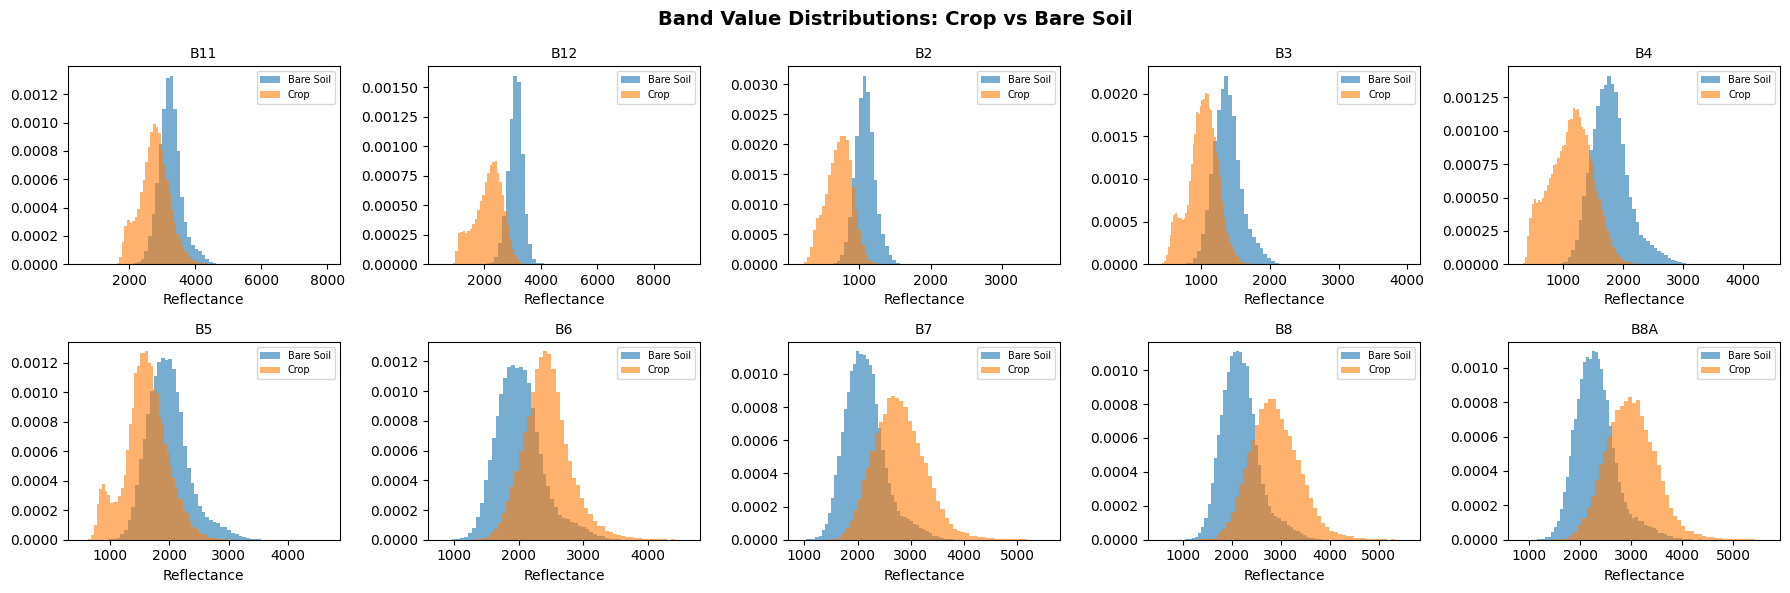

EDA: band distributions saved


In [ ]:
# ── EDA: Band distributions per class (Patiala — train district) ─
df_ann = df_train[df_train['target'] != 0][BAND_COLS + ['target']].copy()
df_ann['class'] = df_ann['target'].map({1: 'Crop', 2: 'Bare Soil'})

fig, axes = plt.subplots(2, 5, figsize=(18, 6))
fig.suptitle('Band Value Distributions: Crop vs Bare Soil', fontsize=14, fontweight='bold')

for ax, band in zip(axes.flat, BAND_COLS):
    for cls, grp in df_ann.groupby('class'):
        vals = grp[band].dropna().sample(min(50000, len(grp)), random_state=42)
        ax.hist(vals, bins=60, alpha=0.6, label=cls, density=True)
    ax.set_title(band, fontsize=10)
    ax.set_xlabel('Reflectance')
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig(f'{BASE_DIR}eda_band_distributions.png', dpi=120)
plt.show()
del df_ann; gc.collect()
print('EDA: band distributions saved')

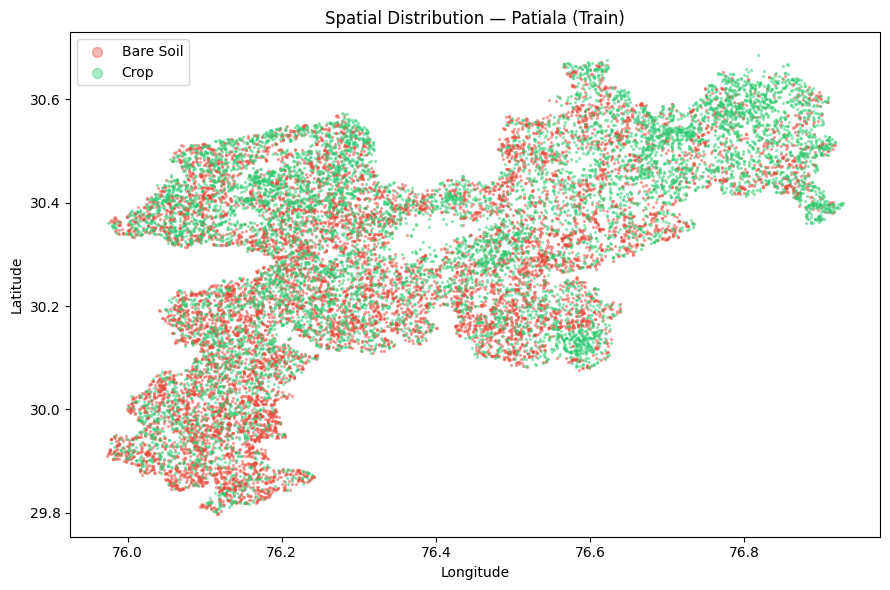

EDA: spatial plot saved


In [ ]:
# ── EDA: Spatial scatter (lat/lon) colored by class ───────────
sample = df_train.sample(min(20000, len(df_train)), random_state=42)
sample = sample.copy()
sample['class'] = sample['target'].map({1: 'Crop', 2: 'Bare Soil'})

fig, ax = plt.subplots(figsize=(9, 6))
colors  = {'Crop': '#2ecc71', 'Bare Soil': '#e74c3c'}
for cls, grp in sample.groupby('class'):
    ax.scatter(grp['longitude'], grp['latitude'], s=2, alpha=0.4,
               color=colors[cls], label=cls)

ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('Spatial Distribution — Patiala (Train)')
ax.legend(markerscale=5)
plt.tight_layout()
plt.savefig(f'{BASE_DIR}eda_spatial.png', dpi=120)
plt.show()

del sample; gc.collect()
print('EDA: spatial plot saved')

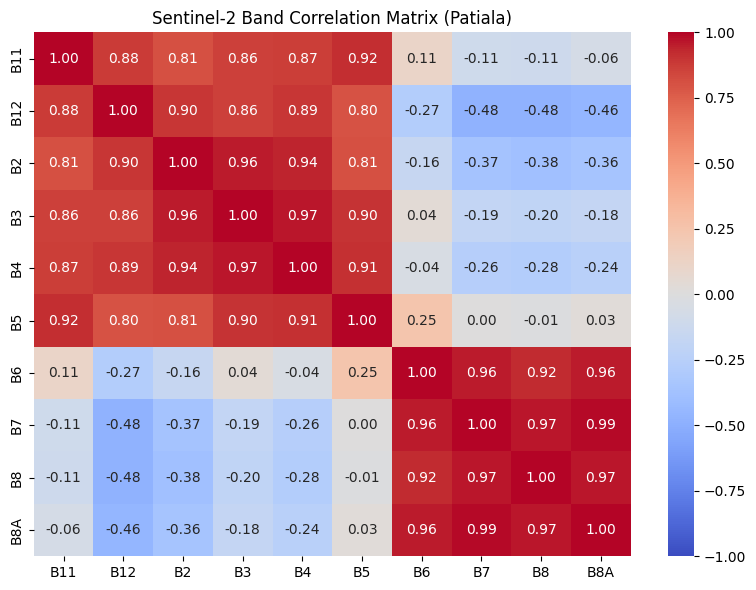

3290

In [ ]:
# ── EDA: Band correlation heatmap ─────────────────────────────
corr_sample = df_train[BAND_COLS].sample(min(100000, len(df_train)), random_state=42)
corr = corr_sample.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax, vmin=-1, vmax=1)
ax.set_title('Sentinel-2 Band Correlation Matrix (Patiala)')
plt.tight_layout()
plt.savefig(f'{BASE_DIR}eda_band_correlation.png', dpi=120)
plt.show()

del corr_sample, corr; gc.collect()

---
## 3. Data Preparation (shared across approaches)

In [ ]:
# ── Filter annotated pixels, binarize ────────────────────────
def prep_district(df):
    # df already has only annotated rows (target != 0) from load_district
    X = df[BAND_COLS].values.astype(np.float32)          # float32, not float64
    y = (df['target'] == 2).values.astype(np.int64)      # bare=1, crop=0
    c = df[['longitude','latitude']].values.astype(np.float32)
    return X, y, c

print(f'RAM before prep: {ram_gb():.1f} GB')
X_train, y_train, coords_train = prep_district(df_train)
del df_train; gc.collect()
print(f'RAM after freeing df_train: {ram_gb():.1f} GB')

X_test,  y_test,  coords_test  = prep_district(df_test)
del df_test; gc.collect()
print(f'RAM after freeing df_test:  {ram_gb():.1f} GB')

print(f'\n── Raw distributions ────────────────────────────────────')
print(f'Train (Patiala)  — total: {len(y_train):,}  bare: {(y_train==1).sum():,} ({100*(y_train==1).mean():.1f}%)  crop: {(y_train==0).sum():,} ({100*(y_train==0).mean():.1f}%)')
print(f'Test  (Amritsar) — total: {len(y_test):,}   bare: {(y_test==1).sum():,}  ({100*(y_test==1).mean():.1f}%)  crop: {(y_test==0).sum():,}  ({100*(y_test==0).mean():.1f}%)')

# ── Balance train set ─────────────────────────────────────────
# If train/test have very different class ratios, balancing prevents
# the model from being biased toward the train-district majority class
if BALANCE_TRAIN:
    rng = np.random.default_rng(SEED)
    bare_idx = np.where(y_train == 1)[0]
    crop_idx = np.where(y_train == 0)[0]
    n        = min(BALANCE_N, len(bare_idx), len(crop_idx))
    sel = np.concatenate([
        rng.choice(bare_idx, n, replace=False),
        rng.choice(crop_idx, n, replace=False)
    ])
    rng.shuffle(sel)
    X_train      = X_train[sel]
    y_train      = y_train[sel]
    coords_train = coords_train[sel]
    gc.collect()
    print(f'\n── After balancing (BALANCE_N={BALANCE_N:,} per class) ──────────')
    print(f'Train — total: {len(y_train):,}  bare: {(y_train==1).sum():,} (50%)  crop: {(y_train==0).sum():,} (50%)')

# Aliases for downstream cells
X_raw  = X_train
y_raw  = y_train
coords = coords_train

# ── Class weights — recompute after balancing ─────────────────
bare_n  = (y_train==1).sum()
crop_n  = (y_train==0).sum()
total_n = bare_n + crop_n
cls_weights = torch.tensor([total_n/crop_n, total_n/bare_n], dtype=torch.float32).to(DEVICE)
print(f'\nClass weights — crop: {cls_weights[0]:.3f}  bare: {cls_weights[1]:.3f}')
print('(weights should both be ~1.0 after balancing)')

RAM before prep: 8.0 GB
RAM after freeing df_train: 8.0 GB
RAM after freeing df_test:  8.0 GB

── Raw distributions ────────────────────────────────────
Train (Patiala)  — total: 3,000,000  bare: 1,597,830 (53.3%)  crop: 1,402,170 (46.7%)
Test  (Amritsar) — total: 1,000,000   bare: 770,806  (77.1%)  crop: 229,194  (22.9%)

── After balancing (BALANCE_N=200,000 per class) ──────────
Train — total: 400,000  bare: 200,000 (50%)  crop: 200,000 (50%)

Class weights — crop: 2.000  bare: 2.000
(weights should both be ~1.0 after balancing)


---
## 🔵 Approach 1 — Baseline: Raw Bands (10-D) → MLP
> Simple MLP on raw Sentinel-2 reflectance values (10 bands). This is our lower-bound baseline.

In [ ]:
# ── Scale raw bands — fit on Patiala, transform both ─────────
print('Fitting RobustScaler on Patiala raw 10 bands...')
scaler_raw = RobustScaler(quantile_range=(10.0, 90.0))
scaler_raw.fit(X_train)

X_scaled_10_tr = scaler_raw.transform(X_train).astype(np.float32)  # Patiala
X_scaled_10_va = scaler_raw.transform(X_test).astype(np.float32)   # Amritsar
print(f'Train scaled: {X_scaled_10_tr.shape}  Test scaled: {X_scaled_10_va.shape}')
print(f'RAM free: {ram_gb():.1f} GB')

# Tensors
X_tr_10 = torch.from_numpy(X_scaled_10_tr)
y_tr    = torch.from_numpy(y_train)
X_va_10 = torch.from_numpy(X_scaled_10_va)
y_va    = torch.from_numpy(y_test)

# num_workers=0 is required on Colab to avoid fork/crash issues
tr_loader_10 = DataLoader(TensorDataset(X_tr_10, y_tr), batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
va_loader_10 = DataLoader(TensorDataset(X_va_10, y_va), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print('DataLoaders ready ✅')

Fitting RobustScaler on Patiala raw 10 bands...
Train scaled: (400000, 10)  Test scaled: (1000000, 10)
RAM free: 8.0 GB
DataLoaders ready ✅


In [ ]:
class MLPClassifier(nn.Module):
    """Generic MLP for binary pixel classification."""
    def __init__(self, in_dim, hidden_dims=(128, 64), num_classes=2, dropout=0.3):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.GELU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, num_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def per_class_metrics(y_true, y_pred, prefix=''):
    from sklearn.metrics import precision_recall_fscore_support, accuracy_score
    acc  = accuracy_score(y_true, y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0,1], zero_division=0)
    return {
        f'{prefix}acc':      acc,
        f'{prefix}crop_p':   p[0],  f'{prefix}crop_r':  r[0],  f'{prefix}crop_f1':  f[0],
        f'{prefix}bare_p':   p[1],  f'{prefix}bare_r':  r[1],  f'{prefix}bare_f1':  f[1],
    }


def print_epoch_metrics(epoch, avg_tr, avg_va, tr_m, va_m, dur, flag):
    print(
        f'{epoch:>5} | loss {avg_tr:.4f}/{avg_va:.4f} | '
        f'acc {100*tr_m["tr_acc"]:.2f}%/{100*va_m["va_acc"]:.2f}% | '
        f'bare F1 {tr_m["tr_bare_f1"]:.4f}/{va_m["va_bare_f1"]:.4f} | '
        f'crop F1 {tr_m["tr_crop_f1"]:.4f}/{va_m["va_crop_f1"]:.4f} | '
        f'{dur:.0f}s{flag}'
    )
    print(
        f'       | bare  P={va_m["va_bare_p"]:.4f}  R={va_m["va_bare_r"]:.4f}  F1={va_m["va_bare_f1"]:.4f}'
        f'   |   crop  P={va_m["va_crop_p"]:.4f}  R={va_m["va_crop_r"]:.4f}  F1={va_m["va_crop_f1"]:.4f}'
    )

def print_final_report(tag, y_true, y_pred):
    """Print full sklearn classification report after training."""
    print(f'\n{"═"*60}')
    print(f'  Final Report — {tag}')
    print(f'  Test district: Amritsar')
    print(f'{"═"*60}')
    print(classification_report(y_true, y_pred, target_names=['Crop (0)', 'Bare (1)'], digits=4))
    cm = confusion_matrix(y_true, y_pred)
    print('Confusion Matrix (rows=true, cols=pred):')
    print(f'               Pred Crop   Pred Bare')
    print(f'  True Crop  :  {cm[0,0]:>9,}   {cm[0,1]:>9,}')
    print(f'  True Bare  :  {cm[1,0]:>9,}   {cm[1,1]:>9,}')
    print(f'  → Bare missed (FN): {cm[1,0]:,}  |  Bare false alarm (FP): {cm[0,1]:,}')


def train_mlp(model, tr_loader, va_loader, epochs, lr, wd, patience, tag=''):
    """Train-val loop with early stopping + per-class metrics every epoch."""
    model = model.to(DEVICE)
    criterion  = nn.CrossEntropyLoss(weight=cls_weights)
    optimizer  = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    best_f1, pat_cnt = 0.0, 0
    history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[],
               'train_f1':[], 'val_f1':[], 'val_bare_p':[], 'val_bare_r':[],
               'val_crop_f1':[], 'val_bare_f1':[]}
    best_state = None
    best_preds = None

    print(f'\n{"═"*80}')
    print(f'  Training: {tag}  |  params: {sum(p.numel() for p in model.parameters()):,}')
    print(f'  Train: Patiala April  →  Test: Amritsar April')
    print(f'{"═"*80}')
    print(f'  Format: epoch | loss tr/va | acc tr/va | bare F1 tr/va | crop F1 tr/va')
    print(f'          [val]  bare P / R / F1   |   crop P / R / F1')
    print('─'*80)

    for epoch in range(1, epochs+1):
        t0 = time.time()

        # ── train
        model.train()
        tr_loss, all_p, all_l = 0.0, [], []
        for x, l in tr_loader:
            x, l = x.to(DEVICE), l.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            out  = model(x)
            loss = criterion(out, l)
            loss.backward(); optimizer.step()
            tr_loss += loss.item()
            all_p.append(out.argmax(1).cpu().numpy())
            all_l.append(l.cpu().numpy())
        scheduler.step()
        tr_m   = per_class_metrics(np.concatenate(all_l), np.concatenate(all_p), 'tr_')
        avg_tr = tr_loss / len(tr_loader)

        # ── val
        model.eval()
        va_loss, all_p, all_l = 0.0, [], []
        with torch.no_grad():
            for x, l in va_loader:
                x, l = x.to(DEVICE), l.to(DEVICE)
                out  = model(x)
                va_loss += criterion(out, l).item()
                all_p.append(out.argmax(1).cpu().numpy())
                all_l.append(l.cpu().numpy())
        va_preds = np.concatenate(all_p)
        va_true  = np.concatenate(all_l)
        va_m     = per_class_metrics(va_true, va_preds, 'va_')
        avg_va   = va_loss / len(va_loader)

        # bookkeeping
        history['train_loss'].append(avg_tr)
        history['val_loss'].append(avg_va)
        history['train_acc'].append(tr_m['tr_acc'])
        history['val_acc'].append(va_m['va_acc'])
        history['train_f1'].append(tr_m['tr_bare_f1'])
        history['val_f1'].append(va_m['va_bare_f1'])
        history['val_bare_p'].append(va_m['va_bare_p'])
        history['val_bare_r'].append(va_m['va_bare_r'])
        history['val_crop_f1'].append(va_m['va_crop_f1'])
        history['val_bare_f1'].append(va_m['va_bare_f1'])

        flag = ' ✓' if va_m['va_bare_f1'] > best_f1 else ''
        print_epoch_metrics(epoch, avg_tr, avg_va, tr_m, va_m, time.time()-t0, flag)
        print('─'*80)

        if va_m['va_bare_f1'] > best_f1:
            best_f1    = va_m['va_bare_f1']
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            best_preds = (va_true.copy(), va_preds.copy())
            pat_cnt    = 0
        else:
            pat_cnt += 1
            if pat_cnt >= patience:
                print(f'  Early stop at epoch {epoch}')
                break

    model.load_state_dict(best_state)
    print_final_report(tag, best_preds[0], best_preds[1])
    return model, history, best_f1


print('MLPClassifier & train_mlp defined ✅')

MLPClassifier & train_mlp defined ✅


In [ ]:
# ── Train baseline (10-D raw bands) ──────────────────────────
mlp_raw = MLPClassifier(in_dim=10, hidden_dims=(128, 64))
mlp_raw, hist_raw, best_f1_raw = train_mlp(
    mlp_raw, tr_loader_10, va_loader_10,
    epochs=EPOCHS_MLP, lr=LR, wd=WEIGHT_DECAY,
    patience=EARLY_PATIENCE, tag='MLP — 10 Raw Bands'
)


════════════════════════════════════════════════════════════════════════════════
  Training: MLP — 10 Raw Bands  |  params: 10,178
  Train: Patiala April  →  Test: Amritsar April
════════════════════════════════════════════════════════════════════════════════
  Format: epoch | loss tr/va | acc tr/va | bare F1 tr/va | crop F1 tr/va
          [val]  bare P / R / F1   |   crop P / R / F1
────────────────────────────────────────────────────────────────────────────────
    1 | loss 0.2957/0.2697 | acc 91.70%/98.14% | bare F1 0.9177/0.9879 | crop F1 0.9163/0.9596 | 24s ✓
       | bare  P=0.9897  R=0.9861  F1=0.9879   |   crop  P=0.9539  R=0.9654  F1=0.9596
────────────────────────────────────────────────────────────────────────────────
    2 | loss 0.0866/0.1327 | acc 99.22%/97.11% | bare F1 0.9922/0.9810 | crop F1 0.9922/0.9402 | 22s
       | bare  P=0.9969  R=0.9656  F1=0.9810   |   crop  P=0.8953  R=0.9899  F1=0.9402
───────────────────────────────────────────────────────────────────────

Running chunked inference on Patiala December...
Total pixels: 43,181,367
  500,000 / 43,181,367
  5,500,000 / 43,181,367
  10,500,000 / 43,181,367
  15,500,000 / 43,181,367
  20,500,000 / 43,181,367
  25,500,000 / 43,181,367
  30,500,000 / 43,181,367
  35,500,000 / 43,181,367
  40,500,000 / 43,181,367

High-conf (>=90%): 36,158,140 (83.7%)
  Predicted bare : 1,389,081
  Predicted crop : 34,769,059


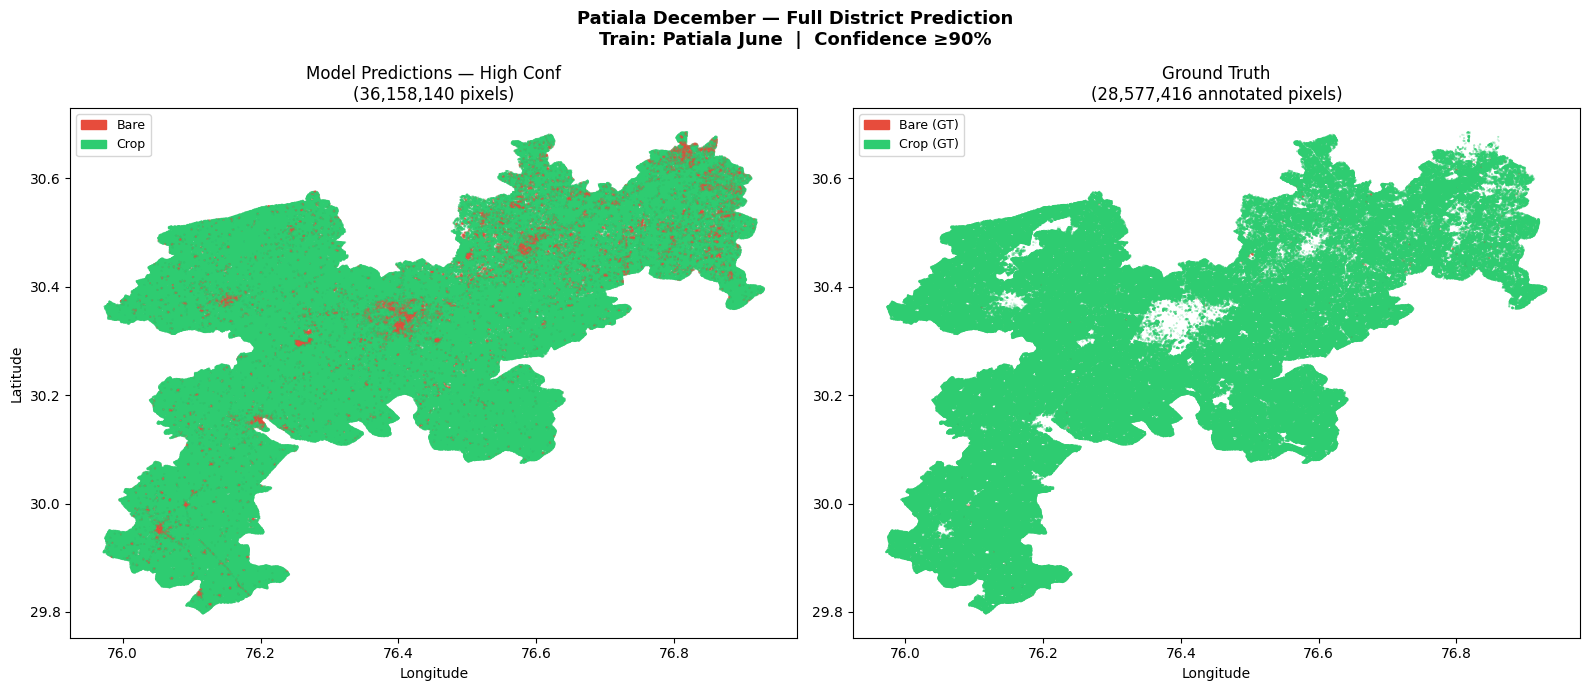

Saved → /content/drive/MyDrive/ILGC-V/patiala_dec_full_prediction_map.png ✅


In [ ]:
# ══════════════════════════════════════════════════════════════
# BONUS: Full-district Deployment — Patiala December (Seasonal Transfer)
# ──────────────────────────────────────────────────────────────
# This cell is a DEPLOYMENT demo, NOT a validation step.
# The model was trained on Patiala/Amritsar May (post-harvest, bare fields).
# Here we apply it to Patiala December (peak rabi — mostly crop).
# Expected: very few bare predictions (~3%) — this is correct for December.
# Purpose: show the model generalises across seasons without retraining.
# ══════════════════════════════════════════════════════════════
# ── Full Patiala December inference — chunked ─────────────────
from matplotlib.patches import Patch
PATIALA_DEC = f'{BASE_DIR}parquet/Patiala/Patiala_S2_December.parquet'
CONFIDENCE_THRESHOLD = 0.90
CHUNK_SIZE = 500_000

print('Running chunked inference on Patiala December...')
mlp_raw.eval()

all_lons, all_lats, all_preds, all_conf, all_targets = [], [], [], [], []

df_iter = pd.read_parquet(PATIALA_DEC,
                          columns=BAND_COLS + ['target','longitude','latitude'])
total = len(df_iter)
print(f'Total pixels: {total:,}')

for start in range(0, total, CHUNK_SIZE):
    chunk   = df_iter.iloc[start:start+CHUNK_SIZE]
    X_chunk = scaler_raw.transform(chunk[BAND_COLS].values.astype(np.float32))

    with torch.no_grad():
        xb    = torch.from_numpy(X_chunk).to(DEVICE)
        probs = torch.softmax(mlp_raw(xb), dim=1).cpu().numpy()

    all_lons.append(chunk['longitude'].values.astype(np.float32))
    all_lats.append(chunk['latitude'].values.astype(np.float32))
    all_targets.append(chunk['target'].values.astype(np.int8))
    all_preds.append(probs.argmax(axis=1).astype(np.int8))
    all_conf.append(probs.max(axis=1).astype(np.float32))

    del chunk, X_chunk, xb, probs; gc.collect()
    if (start // CHUNK_SIZE) % 10 == 0:
        print(f'  {min(start+CHUNK_SIZE, total):,} / {total:,}')

del df_iter; gc.collect()

lons    = np.concatenate(all_lons);    del all_lons
lats    = np.concatenate(all_lats);    del all_lats
targets = np.concatenate(all_targets); del all_targets
preds   = np.concatenate(all_preds);   del all_preds
conf    = np.concatenate(all_conf);    del all_conf
gc.collect()

high_conf = conf >= CONFIDENCE_THRESHOLD
print(f'\nHigh-conf (>={CONFIDENCE_THRESHOLD:.0%}): {high_conf.sum():,} ({100*high_conf.mean():.1f}%)')
print(f'  Predicted bare : {((preds==1)&high_conf).sum():,}')
print(f'  Predicted crop : {((preds==0)&high_conf).sum():,}')

# ── Plot ──────────────────────────────────────────────────────
MAX_PLOT = 1_000_000
rng      = np.random.default_rng(42)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Patiala December — Full District Prediction\n'
             f'Train: Patiala June  |  Confidence ≥{CONFIDENCE_THRESHOLD:.0%}',
             fontsize=13, fontweight='bold')

# Panel 1: high-conf predictions
hc_idx   = np.where(high_conf)[0]
plot_idx = rng.choice(hc_idx, min(MAX_PLOT, len(hc_idx)), replace=False)
color_hc = np.where(preds[plot_idx]==1, '#e74c3c', '#2ecc71')
axes[0].scatter(lons[plot_idx], lats[plot_idx],
                c=color_hc, s=0.05, alpha=0.5, rasterized=True)
axes[0].set_title(f'Model Predictions — High Conf\n({high_conf.sum():,} pixels)')
axes[0].set_xlabel('Longitude'); axes[0].set_ylabel('Latitude')
axes[0].legend(handles=[Patch(color='#e74c3c', label='Bare'),
                          Patch(color='#2ecc71', label='Crop')], fontsize=9)

# Panel 2: ground truth annotated pixels only
ann      = targets != 0
ann_idx  = np.where(ann)[0]
plot_ann = rng.choice(ann_idx, min(MAX_PLOT, len(ann_idx)), replace=False)
color_gt = np.where(targets[plot_ann]==2, '#e74c3c', '#2ecc71')
axes[1].scatter(lons[plot_ann], lats[plot_ann],
                c=color_gt, s=0.05, alpha=0.5, rasterized=True)
axes[1].set_title(f'Ground Truth\n({ann.sum():,} annotated pixels)')
axes[1].set_xlabel('Longitude')
axes[1].legend(handles=[Patch(color='#e74c3c', label='Bare (GT)'),
                          Patch(color='#2ecc71', label='Crop (GT)')], fontsize=9)

plt.tight_layout()
plt.savefig(f'{BASE_DIR}patiala_dec_full_prediction_map.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {BASE_DIR}patiala_dec_full_prediction_map.png ✅')

In [ ]:
# import subprocess
# subprocess.run(['pip', 'install', '-q', 'rasterio'], check=True)
# import rasterio
# from rasterio.transform import from_bounds
# from rasterio.crs import CRS
# import os

# plt.close('all')  # kill any hanging figures

# CONFIDENCE_THRESHOLD = 0.90

# # ── Grid setup ────────────────────────────────────────────────
# lon_min, lon_max = float(lons.min()), float(lons.max())
# lat_min, lat_max = float(lats.min()), float(lats.max())

# unique_lons = np.unique(lons)
# unique_lats = np.unique(lats)
# lon_step = float(np.median(np.diff(unique_lons[:2000])))
# lat_step = float(np.median(np.diff(unique_lats[:2000])))

# n_cols = int(round((lon_max - lon_min) / lon_step)) + 1
# n_rows = int(round((lat_max - lat_min) / lat_step)) + 1
# print(f'Grid: {n_rows} x {n_cols}  |  pixel: {lon_step:.6f}°')

# col_idx = np.clip(np.round((lons - lon_min) / lon_step).astype(np.int32), 0, n_cols-1)
# row_idx = np.clip(np.round((lat_max - lats) / lat_step).astype(np.int32), 0, n_rows-1)

# # ── Build rasters ─────────────────────────────────────────────
# pred_raster = np.full((n_rows, n_cols), 255, dtype=np.uint8)
# pred_raster[row_idx, col_idx] = preds.astype(np.uint8)

# conf_raster = np.full((n_rows, n_cols), 255, dtype=np.uint8)
# conf_raster[row_idx, col_idx] = (conf * 100).astype(np.uint8)

# hc_raster = pred_raster.copy()
# hc_raster[conf_raster < int(CONFIDENCE_THRESHOLD * 100)] = 255  # mask low-conf pixels

# # ── Write GeoTIFF ─────────────────────────────────────────────
# TIFF_PATH = f'{BASE_DIR}patiala_dec_prediction_mask.tif'
# transform = from_bounds(
#     lon_min - lon_step/2, lat_min - lat_step/2,
#     lon_max + lon_step/2, lat_max + lat_step/2,
#     n_cols, n_rows
# )

# with rasterio.open(
#     TIFF_PATH, 'w', driver='GTiff',
#     height=n_rows, width=n_cols, count=3,
#     dtype=np.uint8, crs=CRS.from_epsg(4326),
#     transform=transform, compress='lzw', nodata=255
# ) as dst:
#     dst.write(pred_raster, 1)
#     dst.write(hc_raster,   2)
#     dst.write(conf_raster, 3)
#     dst.update_tags(
#         BAND_1='prediction: 0=crop 1=bare 255=nodata',
#         BAND_2=f'high_conf_prediction >=90pct: 0=crop 1=bare 255=nodata',
#         BAND_3='confidence: 0-100 scaled 255=nodata',
#         TRAIN='Patiala_June', TEST='Patiala_December', MODEL='MLP_10band_raw'
#     )

# print(f'Saved → {TIFF_PATH}')
# print(f'Size  : {os.path.getsize(TIFF_PATH)/1e6:.1f} MB')
# print(f'Bands : 1=all predictions  |  2=high-conf ≥90%  |  3=confidence 0-100')
# print(f'\nIn GEE upload the asset then:')
# print(f'  var m = ee.Image("your_asset");')
# print(f'  Map.addLayer(m.select("b2"), {{min:0,max:1,palette:["00cc44","e74c3c"]}}, "Bare Soil");')

---
## 🟢 Approach 2 — Spectral MAE Encoder (32-D) → MLP
> We replace raw 10-D bands with 32-D CLS embeddings from the pre-trained Spectral MAE encoder. The encoder learned rich spectral representations via masked reconstruction.

In [ ]:
# ── SpectralMAE model definition ──────────────────────────────
# IMPORTANT: lambda_nm_const and fwhm_nm_const are stored as plain
# tensors (NOT register_buffer) because the checkpoint was saved
# without them as buffers. Using register_buffer causes missing-key
# errors on load. Plain tensors are manually moved to device in Cell 22.

import math

class SpectralMetaEmbedding(nn.Module):
    def __init__(self, embed_dim, fourier_features=16, lam_min_nm=400., lam_max_nm=2500.):
        super().__init__()
        self.ff = fourier_features
        self.lam_min = lam_min_nm; self.lam_max = lam_max_nm
        in_dim = 2 + 2 * fourier_features
        self.mlp = nn.Sequential(nn.Linear(in_dim, 128), nn.GELU(), nn.Linear(128, embed_dim))

    def forward(self, lambda_nm, fwhm_nm):
        lam  = (lambda_nm - self.lam_min) / (self.lam_max - self.lam_min)
        fwhm = fwhm_nm / (self.lam_max - self.lam_min)
        k    = torch.arange(1, self.ff + 1, device=lam.device, dtype=lam.dtype)[None, None, :]
        ang  = 2 * math.pi * lam.unsqueeze(-1) * k
        phi  = torch.cat([torch.sin(ang), torch.cos(ang)], dim=-1)
        feat = torch.cat([lam.unsqueeze(-1), fwhm.unsqueeze(-1), phi], dim=-1)
        return self.mlp(feat)


def sample_band_mask(B, C, mask_ratio, device):
    K        = int(round((1. - mask_ratio) * C))
    noise    = torch.rand(B, C, device=device)
    ids      = torch.argsort(noise, dim=1)
    ids_keep = ids[:, :K]; ids_mask = ids[:, K:]
    mask     = torch.zeros(B, C, dtype=torch.bool, device=device)
    mask.scatter_(1, ids_mask, True)
    return mask, ids_keep, ids_mask


class SpectralMAEEncoder(nn.Module):
    def __init__(self, num_bands, embed_dim, enc_depth, enc_heads,
                 lambda_nm, fwhm_nm, fourier_features=16,
                 lam_min_nm=400., lam_max_nm=2500.):
        super().__init__()
        self.C = num_bands; D = embed_dim
        # Plain tensors — NOT register_buffer (checkpoint was saved without them as buffers)
        self.lambda_nm_const = torch.tensor(lambda_nm, dtype=torch.float32)
        self.fwhm_nm_const   = torch.tensor(fwhm_nm,   dtype=torch.float32)
        self.value_proj      = nn.Linear(1, D)
        self.cls             = nn.Parameter(torch.zeros(1, 1, D))
        nn.init.trunc_normal_(self.cls, std=0.02)
        self.meta            = SpectralMetaEmbedding(D, fourier_features, lam_min_nm, lam_max_nm)
        self.enc_mask_token  = nn.Parameter(torch.zeros(1, 1, D))
        nn.init.trunc_normal_(self.enc_mask_token, std=0.02)
        layer = nn.TransformerEncoderLayer(d_model=D, nhead=enc_heads, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=enc_depth)

    def forward(self, x, mask_ratio=0.0):
        B, C = x.shape; D = self.cls.shape[-1]
        tok  = self.value_proj(x.unsqueeze(-1))
        lam  = self.lambda_nm_const.to(x.device).unsqueeze(0).expand(B, C)
        wid  = self.fwhm_nm_const.to(x.device).unsqueeze(0).expand(B, C)
        tok  = tok + self.meta(lam, wid)
        mask, ids_keep, ids_mask = sample_band_mask(B, C, mask_ratio, x.device)
        tok_vis = torch.gather(tok, 1, ids_keep.unsqueeze(-1).expand(-1, -1, D))
        cls_in  = self.cls.expand(B, 1, D)
        enc_out = self.encoder(torch.cat([cls_in, tok_vis], dim=1))
        cls_out = enc_out[:, 0, :]
        vis_out = enc_out[:, 1:, :]
        band_enc = torch.zeros(B, C, D, device=x.device, dtype=x.dtype)
        band_enc.scatter_(1, ids_keep.unsqueeze(-1).expand(-1, -1, D), vis_out)
        return {'cls': cls_out, 'band_enc': band_enc, 'mask': mask,
                'ids_keep': ids_keep, 'ids_mask': ids_mask}


class SpectralMAEDecoder(nn.Module):
    def __init__(self, num_bands, enc_dim, dec_dim, dec_depth, dec_heads,
                 lambda_nm, fwhm_nm, include_cls=True,
                 fourier_features=16, lam_min=400., lam_max=2500.):
        super().__init__()
        self.include_cls = include_cls
        # Plain tensors — NOT register_buffer
        self.lambda_nm_const = torch.tensor(lambda_nm, dtype=torch.float32)
        self.fwhm_nm_const   = torch.tensor(fwhm_nm,   dtype=torch.float32)
        self.mem_proj        = nn.Linear(enc_dim, dec_dim)
        self.dec_mask_token  = nn.Parameter(torch.zeros(1, 1, dec_dim))
        nn.init.trunc_normal_(self.dec_mask_token, std=0.02)
        self.meta_q = SpectralMetaEmbedding(dec_dim, fourier_features, lam_min, lam_max)
        self.meta_m = SpectralMetaEmbedding(dec_dim, fourier_features, lam_min, lam_max)
        layer = nn.TransformerDecoderLayer(d_model=dec_dim, nhead=dec_heads, batch_first=True, norm_first=True)
        self.decoder = nn.TransformerDecoder(layer, num_layers=dec_depth)
        self.head    = nn.Linear(dec_dim, 1)

    def forward(self, enc_band, enc_cls, mask, ids_keep, ids_mask):
        B, C, D = enc_band.shape; dec_dim = self.head.in_features
        mem_vis = torch.gather(enc_band, 1, ids_keep.unsqueeze(-1).expand(-1, -1, D))
        mem = mem_vis
        if self.include_cls:
            mem = torch.cat([enc_cls.unsqueeze(1), mem], dim=1)
        mem = self.mem_proj(mem)
        lam = self.lambda_nm_const.to(enc_band.device).unsqueeze(0).expand(B, C)
        wid = self.fwhm_nm_const.to(enc_band.device).unsqueeze(0).expand(B, C)
        lam_v  = torch.gather(lam, 1, ids_keep)
        wid_v  = torch.gather(wid, 1, ids_keep)
        meta_v = self.meta_m(lam_v, wid_v)
        if self.include_cls:
            meta_v = torch.cat([torch.zeros(B, 1, dec_dim, device=enc_band.device), meta_v], dim=1)
        mem = mem + meta_v
        M   = ids_mask.shape[1]
        q   = self.dec_mask_token.expand(B, M, dec_dim)
        lam_m = torch.gather(lam, 1, ids_mask)
        wid_m = torch.gather(wid, 1, ids_mask)
        q   = q + self.meta_q(lam_m, wid_m)
        dec_out = self.decoder(tgt=q, memory=mem)
        pred_m  = self.head(dec_out).squeeze(-1)
        out = torch.zeros(B, C, device=enc_band.device, dtype=pred_m.dtype)
        out.scatter_(1, ids_mask, pred_m)
        return out


class SpectralMAE(nn.Module):
    def __init__(self, num_bands, embed_dim, enc_depth, enc_heads,
                 dec_dim, dec_depth, dec_heads,
                 lambda_nm, fwhm_nm,
                 fourier_features=16, lam_min_nm=400., lam_max_nm=2500.,
                 include_cls_in_memory=True):
        super().__init__()
        self.encoder = SpectralMAEEncoder(
            num_bands, embed_dim, enc_depth, enc_heads,
            lambda_nm, fwhm_nm, fourier_features, lam_min_nm, lam_max_nm
        )
        self.decoder = SpectralMAEDecoder(
            num_bands, embed_dim, dec_dim, dec_depth, dec_heads,
            lambda_nm, fwhm_nm, include_cls_in_memory,
            fourier_features, lam_min_nm, lam_max_nm
        )

    def forward(self, x, mask_ratio=0.6):
        enc  = self.encoder(x, mask_ratio)
        pred = self.decoder(enc['band_enc'], enc['cls'], enc['mask'],
                            enc['ids_keep'], enc['ids_mask'])
        return {'cls': enc['cls'], 'pred_masked': pred, **enc}

print('SpectralMAE model classes defined ✅')

SpectralMAE model classes defined ✅


In [ ]:
# ── Load pre-trained encoder ───────────────────────────────────
mae_model = SpectralMAE(
    num_bands=NUM_BANDS,
    embed_dim=EMBED_DIM, enc_depth=ENC_DEPTH, enc_heads=ENC_HEADS,
    dec_dim=DEC_DIM,     dec_depth=DEC_DEPTH, dec_heads=DEC_HEADS,
    lambda_nm=LAMBDAS_NM, fwhm_nm=FWHM_NM,
    fourier_features=FOURIER_FF
).to(DEVICE)

ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
mae_model.load_state_dict(ckpt, strict=True)
mae_model.eval()

# lambda/fwhm tensors are not registered buffers so .to(DEVICE) above
# didn't move them — move manually here.
mae_model.encoder.lambda_nm_const = mae_model.encoder.lambda_nm_const.to(DEVICE)
mae_model.encoder.fwhm_nm_const   = mae_model.encoder.fwhm_nm_const.to(DEVICE)
mae_model.decoder.lambda_nm_const = mae_model.decoder.lambda_nm_const.to(DEVICE)
mae_model.decoder.fwhm_nm_const   = mae_model.decoder.fwhm_nm_const.to(DEVICE)

enc_params = sum(p.numel() for p in mae_model.encoder.parameters())
print(f'Encoder loaded ✅  params: {enc_params:,}')
print(f'Checkpoint: {CKPT_PATH}')

Encoder loaded ✅  params: 833,760
Checkpoint: /content/drive/MyDrive/ILGC-V/stitched/Patiala/spectral_mae_ckpt_32.pt


In [ ]:
# ── Scale with the encoder's own saved scaler ──────────────────
# The MAE scaler was fitted with bands in BAND_COLS order (B11 first).
# X_train was loaded using the same BAND_COLS order (Cell 6 fixed),
# so this transform is now correctly aligned column-by-column.
scaler_mae = joblib.load(SCALER_PATH)
print(f'Loaded encoder scaler from: {SCALER_PATH}')
print(f'Scaler expects {scaler_mae.n_features_in_} features in order: {BAND_COLS}')

X_scaled_mae_tr = scaler_mae.transform(X_train).astype(np.float32)  # Patiala
X_scaled_mae_va = scaler_mae.transform(X_test).astype(np.float32)   # Amritsar

print(f'Scaled train: {X_scaled_mae_tr.shape}  Scaled test: {X_scaled_mae_va.shape}')

# Sanity check: column 0 median should be ~1 (robust-scaled B11 SWIR)
# If it is far from 0, band order is still wrong.
col0_med = float(np.median(X_scaled_mae_tr[:, 0]))
print(f'Col-0 median after scaling (should be ~0.0 for B11): {col0_med:.3f}')

# ── Extract CLS embeddings (32-D) in batches ──────────────────
@torch.no_grad()
def extract_cls_embeddings(model, X_np, batch_size=8192):
    """Forward encoder with mask_ratio=0 to get deterministic CLS tokens."""
    model.eval()
    embeds = []
    for i in tqdm(range(0, len(X_np), batch_size), desc='Encoding CLS'):
        xb   = torch.from_numpy(X_np[i:i+batch_size]).to(DEVICE)
        enc  = model.encoder(xb, mask_ratio=0.0)
        embeds.append(enc['cls'].cpu().numpy())
    return np.concatenate(embeds, axis=0)

print('Extracting CLS embeddings for Patiala (train)...')
X_cls_tr = extract_cls_embeddings(mae_model, X_scaled_mae_tr)
print('Extracting CLS embeddings for Amritsar (test)...')
X_cls_va = extract_cls_embeddings(mae_model, X_scaled_mae_va)
print(f'Train CLS: {X_cls_tr.shape}  Test CLS: {X_cls_va.shape}')


Loaded encoder scaler from: /content/drive/MyDrive/ILGC-V/stitched/Patiala/spectral_scaler_32.joblib
Scaler expects 10 features in order: ['B11', 'B12', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A']
Scaled train: (400000, 10)  Scaled test: (1000000, 10)
Col-0 median after scaling (should be ~0.0 for B11): 0.286
Extracting CLS embeddings for Patiala (train)...


Encoding CLS:   0%|          | 0/49 [00:00<?, ?it/s]

In [ ]:
# ── Build DataLoaders for 32-D embeddings ──────────────────────
X_tr_32  = torch.from_numpy(X_cls_tr)
X_va_32  = torch.from_numpy(X_cls_va)

# num_workers=0 required on Colab
tr_loader_32 = DataLoader(TensorDataset(X_tr_32, y_tr), batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
va_loader_32 = DataLoader(TensorDataset(X_va_32, y_va), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print('DataLoaders (32-D) ready ✅')

In [ ]:
# ── Train MLP on 32-D MAE embeddings ─────────────────────────
mlp_cls = MLPClassifier(in_dim=32, hidden_dims=(128, 64))
mlp_cls, hist_cls, best_f1_cls = train_mlp(
    mlp_cls, tr_loader_32, va_loader_32,
    epochs=EPOCHS_MLP, lr=LR, wd=WEIGHT_DECAY,
    patience=EARLY_PATIENCE, tag='MLP — 32-D MAE Embeddings'
)

---
## 🟡 Approach 3 — Random Forest on 32-D MAE Embeddings
> Non-neural baseline using scikit-learn RF on the same CLS embeddings — tests whether the representations are linearly/simply separable.

In [ ]:
# ── Subsample for RF (RAM-friendly) ───────────────────────────
RF_TRAIN_SAMPLES = min(500_000, len(X_cls_tr))
rf_sub  = np.random.default_rng(SEED).choice(len(X_cls_tr), RF_TRAIN_SAMPLES, replace=False)

X_rf_tr = X_cls_tr[rf_sub]
y_rf_tr = y_train[rf_sub]
X_rf_va = X_cls_va
y_rf_va = y_test

print(f'RF Train: {X_rf_tr.shape}  Val: {X_rf_va.shape}')

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    class_weight='balanced',
    n_jobs=-1,
    random_state=SEED
)
print('Training Random Forest...')
t0 = time.time()
rf.fit(X_rf_tr, y_rf_tr)
print(f'RF trained in {time.time()-t0:.1f}s')

y_pred_rf = rf.predict(X_rf_va)
best_f1_rf = f1_score(y_rf_va, y_pred_rf, pos_label=1)
print(f'\nRF — Val bare-soil F1: {best_f1_rf:.4f}')
print(classification_report(y_rf_va, y_pred_rf, target_names=['Crop','Bare']))

---
## 🔴 Approach 4 — Ablation Studies
> Systematically test: (a) which bands matter most, (b) effect of embedding dimension, (c) deeper MLP.

In [ ]:
# ── 4a: Band Importance (RF feature importance) ───────────────
importances = rf.feature_importances_  # shape (32,)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(32), importances, color='steelblue', edgecolor='navy', alpha=0.8)
ax.set_xlabel('CLS Embedding Dimension Index')
ax.set_ylabel('Mean Decrease in Impurity')
ax.set_title('Feature Importance of 32-D CLS Embeddings (Random Forest)')
plt.tight_layout()
plt.savefig(f'{BASE_DIR}feature_importance_32d.png', dpi=120)
plt.show()
print('Feature importance plot saved')

In [ ]:
# ── 4b: RF on raw bands — which S2 bands matter most? ─────────
rf_raw = RandomForestClassifier(
    n_estimators=200, max_depth=10, class_weight='balanced',
    n_jobs=-1, random_state=SEED
)
X_raw_tr_sub = X_scaled_10_tr[rf_sub]
print('Training RF on raw 10 bands...')
rf_raw.fit(X_raw_tr_sub, y_rf_tr)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(BAND_COLS, rf_raw.feature_importances_, color='tomato', edgecolor='darkred', alpha=0.8)
ax.set_xlabel('Sentinel-2 Band')
ax.set_ylabel('Importance')
ax.set_title('Band Importance — RF on Raw 10 Bands')
plt.tight_layout()
plt.savefig(f'{BASE_DIR}stitched/Patiala/band_importance_raw.png', dpi=120)
plt.show()

y_pred_raw_rf = rf_raw.predict(X_scaled_10_va)
f1_raw_rf     = f1_score(y_test, y_pred_raw_rf, pos_label=1)
print(f'RF on raw bands F1 (Amritsar): {f1_raw_rf:.4f}')

In [ ]:
# ── 4c: Deeper MLP on 32-D embeddings ─────────────────────────
mlp_deep = MLPClassifier(in_dim=32, hidden_dims=(256, 128, 64), dropout=0.2)
mlp_deep, hist_deep, best_f1_deep = train_mlp(
    mlp_deep, tr_loader_32, va_loader_32,
    epochs=EPOCHS_MLP, lr=LR, wd=WEIGHT_DECAY,
    patience=EARLY_PATIENCE, tag='Deep MLP 256-128-64 — 32-D MAE Embeddings'
)

---
## 📊 Comparison — All Approaches

In [ ]:
# ── Training curves for MLP approaches ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('MLP Training Curves Comparison', fontsize=14, fontweight='bold')

pairs = [
    ('Loss',     'train_loss', 'val_loss',  'Loss',     None),
    ('Accuracy', 'train_acc',  'val_acc',   'Accuracy (%)', (0,100)),
    ('Bare F1',  'train_f1',   'val_f1',    'F1 Score', (0,1)),
]

configs = [
    (hist_raw,  '10-D Raw',         '#3498db', '--'),
    (hist_cls,  '32-D MAE CLS',     '#2ecc71', '-'),
    (hist_deep, '32-D MAE Deep MLP','#e74c3c', '-'),
]

for ax, (title, tr_key, va_key, ylabel, ylim) in zip(axes, pairs):
    for hist, label, color, ls in configs:
        eps = list(range(1, len(hist[tr_key])+1))
        ax.plot(eps, hist[tr_key], color=color, linestyle=':', alpha=0.7)
        ax.plot(eps, hist[va_key], color=color, linestyle=ls, label=label)
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel)
    if ylim: ax.set_ylim(*ylim)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{BASE_DIR}training_curves_comparison.png', dpi=120)
plt.show()

---
## 🔬 Embedding Visualization — t-SNE
> Visualize how well the raw bands vs MAE embeddings separate crop vs bare.

In [ ]:
from sklearn.manifold import TSNE

N_TSNE = 5000
# Visualize on Amritsar (test district) — unseen during training
sample_idx = np.random.default_rng(SEED).choice(len(y_test), min(N_TSNE, len(y_test)), replace=False)
y_tsne = y_test[sample_idx]

# Raw 10-D
X_tsne_raw = X_scaled_10_va[sample_idx]
# MAE 32-D
X_tsne_cls = X_cls_va[sample_idx]

print('Running t-SNE on raw 10-D...')
Z_raw = TSNE(n_components=2, perplexity=35, random_state=SEED, init='random').fit_transform(X_tsne_raw)
print('Running t-SNE on 32-D MAE CLS...')
Z_cls = TSNE(n_components=2, perplexity=35, random_state=SEED, init='random').fit_transform(X_tsne_cls)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('t-SNE Embedding Comparison — Amritsar (Test District, Unseen)', fontsize=14, fontweight='bold')

cmap = {0: '#2ecc71', 1: '#e74c3c'}
clbl = {0: 'Crop', 1: 'Bare'}

for ax, Z, title in [(axes[0], Z_raw, 'Raw Bands (10-D)'),
                     (axes[1], Z_cls, 'MAE CLS Embeddings (32-D)')]:
    for cls_id in [0, 1]:
        mask = y_tsne == cls_id
        ax.scatter(Z[mask,0], Z[mask,1], s=4, alpha=0.5,
                   color=cmap[cls_id], label=clbl[cls_id])
    ax.set_title(title, fontsize=12)
    ax.legend(markerscale=4, fontsize=10)
    ax.set_xlabel('t-SNE dim 1'); ax.set_ylabel('t-SNE dim 2')

plt.tight_layout()
plt.savefig(f'{BASE_DIR}tsne_comparison.png', dpi=120)
plt.show()
print('t-SNE plot saved ✅')

---
## 📋 Detailed Evaluation — Best Model

In [ ]:
# ── Full val evaluation on best MLP ───────────────────────────
# Use mlp_cls (MAE 32-D) as the best neural model
best_model = mlp_cls  # swap to mlp_deep if that wins
best_model.eval()

all_preds, all_probs, all_labels = [], [], []
with torch.no_grad():
    for x, l in tqdm(va_loader_32, desc='Full eval'):
        x    = x.to(DEVICE)
        logits = best_model(x)
        probs  = F.softmax(logits, dim=1)[:, 1]  # P(bare)
        preds  = logits.argmax(1)
        all_preds.append(preds.cpu().numpy())
        all_probs.append(probs.cpu().numpy())
        all_labels.append(l.numpy())

all_preds  = np.concatenate(all_preds)
all_probs  = np.concatenate(all_probs)
all_labels = np.concatenate(all_labels)

print('── Classification Report (MAE 32-D → MLP) ───────────────')
print(classification_report(all_labels, all_preds, target_names=['Crop','Bare']))

# Confusion matrix + ROC + PR
cm = confusion_matrix(all_labels, all_preds)
auc = roc_auc_score(y_test, all_probs)
ap  = average_precision_score(y_test, all_probs)
print(f'AUC-ROC: {auc:.4f}   AP: {ap:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Confusion matrix
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=axes[0],
            xticklabels=['Crop','Bare'], yticklabels=['Crop','Bare'])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')
axes[0].set_title('Confusion Matrix — MAE MLP (Test: Amritsar)')

# Precision-Recall curve
prec, rec, _ = precision_recall_curve(y_test, all_probs)
axes[1].plot(rec, prec, color='darkorange', lw=2, label=f'AP={ap:.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve (Bare Soil)')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{BASE_DIR}evaluation_plots.png', dpi=120)
plt.show()

---
## 🗺️ Spatial Prediction Map
> Visualize model predictions on the validation pixels geospatially.

In [ ]:
va_coords = coords_test
N_MAP     = min(50000, len(va_coords))
map_idx   = np.random.default_rng(SEED).choice(len(va_coords), N_MAP, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Spatial Prediction Map — Amritsar (Test District)', fontsize=14, fontweight='bold')

cmap_cls = {0: '#2ecc71', 1: '#e74c3c'}
titles   = ['Ground Truth', 'MLP Prediction (MAE 32-D, trained on Patiala)']
arrays   = [y_test[map_idx], all_preds[map_idx]]

for ax, title, arr in zip(axes, titles, arrays):
    lons = va_coords[map_idx, 0]
    lats = va_coords[map_idx, 1]
    colors_arr = [cmap_cls[int(v)] for v in arr]
    ax.scatter(lons, lats, c=colors_arr, s=1, alpha=0.6)
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    ax.set_title(title)
    from matplotlib.patches import Patch
    legend_elements = [Patch(color='#2ecc71', label='Crop'),
                       Patch(color='#e74c3c', label='Bare')]
    ax.legend(handles=legend_elements, markerscale=5, fontsize=9)

plt.tight_layout()
plt.savefig(f'{BASE_DIR}spatial_prediction_map.png', dpi=150)
plt.show()
print('Spatial map saved ✅')

---
## 🚀 Approach 5 — SegFormer (Final: Spatial Context)
> SegFormer is a transformer-based semantic segmentation model. Unlike pixel-wise MLP, it captures spatial neighbourhoods — critical for detecting contiguous bare soil patches.
>
> **Architecture:** Hierarchical Mix Transformer (MiT) encoder → lightweight All-MLP decoder → per-pixel logits

### How we adapt SegFormer for Sentinel-2:
```
S2 patch [H×W×10 bands]
    → Conv stem (10→3 or 10→in_channels)     ← we patch the first conv
    → MiT encoder (hierarchical attention)
    → All-MLP decoder
    → [H×W×2] logits (crop / bare)
```

In [ ]:
from transformers import SegformerConfig, SegformerForSemanticSegmentation

class S2PatchDataset(torch.utils.data.Dataset):
    """
    Geographic sliding window patch dataset for SegFormer.
    Non-overlapping 256x256 tiles over the district.

    Stores only pixel indices per tile — builds patches on-the-fly in __getitem__.
    This keeps RAM usage proportional to the number of pixels, not patches.
    """
    def __init__(self, X_bands, y_labels, coords, patch_size=256,
                 augment=False, min_annotated_frac=0.05):
        """
        X_bands   : (N, C) float32 — already scaled bands or embeddings
        y_labels  : (N,) int64     — 0=crop, 1=bare
        coords    : (N, 2) float32 — [lon, lat]
        """
        self.patch_size = patch_size
        self.augment    = augment
        self.C          = X_bands.shape[1]
        self.X          = X_bands   # store reference, not copy
        self.y          = y_labels
        P               = patch_size

        lon = coords[:, 0].astype(np.float64)
        lat = coords[:, 1].astype(np.float64)

        lon_min, lon_max = lon.min(), lon.max()
        lat_min, lat_max = lat.min(), lat.max()

        # Infer native pixel step
        u_lon = np.unique(lon)
        u_lat = np.unique(lat)
        lon_step = float(np.median(np.diff(u_lon[:min(5000, len(u_lon))]))) if len(u_lon) > 1 else 1e-4
        lat_step = float(np.median(np.diff(u_lat[:min(5000, len(u_lat))]))) if len(u_lat) > 1 else 1e-4

        tile_lon = P * lon_step
        tile_lat = P * lat_step

        print(f'  Pixel step: lon={lon_step:.6f}°  lat={lat_step:.6f}°')
        print(f'  Tile size : {tile_lon:.4f}° x {tile_lat:.4f}°  ({P}x{P} pixels)')

        tile_lon_starts = np.arange(lon_min, lon_max, tile_lon)
        tile_lat_starts = np.arange(lat_min, lat_max, tile_lat)
        print(f'  Candidate tiles: {len(tile_lon_starts) * len(tile_lat_starts)}')

        # For each valid tile, store: (lon0, lat0, pixel_indices, row_idx, col_idx)
        # This is lightweight — just indices, no band data
        self.tile_meta = []

        for lat0 in tile_lat_starts:
            for lon0 in tile_lon_starts:
                lon1 = lon0 + tile_lon
                lat1 = lat0 + tile_lat

                in_tile = np.where(
                    (lon >= lon0) & (lon < lon1) &
                    (lat >= lat0) & (lat < lat1)
                )[0]

                if len(in_tile) == 0:
                    continue

                ann_frac = (y_labels[in_tile] >= 0).mean()
                if ann_frac < min_annotated_frac:
                    continue

                # Precompute grid positions for pixels in this tile
                tile_lons = lon[in_tile]
                tile_lats = lat[in_tile]

                col_idx = np.clip(
                    np.round((tile_lons - lon0) / tile_lon * (P - 1)).astype(np.int32),
                    0, P - 1
                )
                row_idx = np.clip(
                    np.round((lat1 - tile_lats) / tile_lat * (P - 1)).astype(np.int32),
                    0, P - 1
                )

                self.tile_meta.append((in_tile, row_idx, col_idx, lon0, lat0))

        print(f'  Valid patches : {len(self.tile_meta)} (min_annotated_frac={min_annotated_frac})')

    def __len__(self):
        return len(self.tile_meta)

    def __getitem__(self, idx):
        in_tile, row_idx, col_idx, _, _ = self.tile_meta[idx]
        P = self.patch_size

        img = np.zeros((P, P, self.C), dtype=np.float32)
        lbl = np.full((P, P), -1, dtype=np.int64)
        cnt = np.zeros((P, P), dtype=np.int32)

        tile_X = self.X[in_tile]
        tile_y = self.y[in_tile]

        # Vectorized accumulation for averaging
        np.add.at(img, (row_idx, col_idx), tile_X)
        np.add.at(cnt, (row_idx, col_idx), 1)

        # For labels: annotated takes priority
        # Process unannotated first, then overwrite with annotated
        order = np.argsort(tile_y)  # unannotated (-1) first, then 0, then 1
        for i in order:
            r, c = row_idx[i], col_idx[i]
            if tile_y[i] >= 0:
                lbl[r, c] = tile_y[i]

        # Normalize averaged bins
        filled = cnt > 0
        img[filled] /= cnt[filled, np.newaxis]

        img = torch.from_numpy(img.transpose(2, 0, 1))  # [C, P, P]
        lbl = torch.from_numpy(lbl)                      # [P, P]

        if self.augment:
            if torch.rand(1).item() > 0.5:
                img = img.flip(-1); lbl = lbl.flip(-1)
            if torch.rand(1).item() > 0.5:
                img = img.flip(-2); lbl = lbl.flip(-2)

        return img, lbl

print('S2PatchDataset defined ✅ (lazy loading — RAM efficient)')

In [ ]:
PATCH_SIZE = 256
SEG_BATCH  = 8

# Scale once here, outside the dataset — dataset stores only the scaled arrays
X_raw_scaled  = X_scaled_10_tr
X_test_scaled = X_scaled_10_va
# X_cls_tr / X_cls_va already in embedding space — no scaling needed

# ── Version 1: Raw 10-band ─────────────────────────────────────
print('=== Version 1: Raw 10-band patches ===')
print('Building train patches (Patiala)...')
tr_patch_ds_10 = S2PatchDataset(X_raw_scaled,  y_raw,   coords,      PATCH_SIZE, augment=True)
print('Building test patches (Amritsar)...')
va_patch_ds_10 = S2PatchDataset(X_test_scaled, y_test,  coords_test, PATCH_SIZE, augment=False)

tr_seg_loader_10 = DataLoader(tr_patch_ds_10, batch_size=SEG_BATCH, shuffle=True,  num_workers=0)
va_seg_loader_10 = DataLoader(va_patch_ds_10, batch_size=SEG_BATCH, shuffle=False, num_workers=0)
print(f'10-band — train: {len(tr_seg_loader_10)} batches  test: {len(va_seg_loader_10)} batches')

# ── Version 2: 32-D MAE embeddings ────────────────────────────
print('\n=== Version 2: 32-D MAE embedding patches ===')
print('Building train patches (Patiala)...')
tr_patch_ds_32 = S2PatchDataset(X_cls_tr, y_raw,  coords,      PATCH_SIZE, augment=True)
print('Building test patches (Amritsar)...')
va_patch_ds_32 = S2PatchDataset(X_cls_va, y_test, coords_test, PATCH_SIZE, augment=False)

tr_seg_loader_32 = DataLoader(tr_patch_ds_32, batch_size=SEG_BATCH, shuffle=True,  num_workers=0)
va_seg_loader_32 = DataLoader(va_patch_ds_32, batch_size=SEG_BATCH, shuffle=False, num_workers=0)
print(f'32-dim — train: {len(tr_seg_loader_32)} batches  test: {len(va_seg_loader_32)} batches')

In [ ]:
def build_segformer_s2(num_input_channels, num_labels=2, image_size=256):
    config = SegformerConfig(
        num_channels=num_input_channels,
        num_labels=num_labels,
        image_size=image_size,
        # B0 settings
        depths=[2, 2, 2, 2],
        hidden_sizes=[32, 64, 160, 256],
        num_attention_heads=[1, 2, 5, 8],
        decoder_hidden_size=256,
    )
    return SegformerForSemanticSegmentation(config)

segformer_10 = build_segformer_s2(num_input_channels=10).to(DEVICE)
segformer_32 = build_segformer_s2(num_input_channels=32).to(DEVICE)

print(f'SegFormer-10band params: {sum(p.numel() for p in segformer_10.parameters()):,}')
print(f'SegFormer-32dim  params: {sum(p.numel() for p in segformer_32.parameters()):,}')

In [ ]:
def train_segformer(model, tr_loader, va_loader, tag, epochs=10, lr=6e-5, patience=3):
    opt   = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=lr, steps_per_epoch=len(tr_loader), epochs=epochs
    )
    criterion = nn.CrossEntropyLoss(weight=cls_weights, ignore_index=-1)

    def run_epoch(loader, train):
        model.train() if train else model.eval()
        total_loss = 0.
        all_p, all_l = [], []
        ctx = torch.enable_grad() if train else torch.no_grad()
        with ctx:
            for imgs, lbls in tqdm(loader, desc=tag, leave=False):
                imgs = imgs.to(DEVICE); lbls = lbls.to(DEVICE)
                logits = F.interpolate(
                    model(pixel_values=imgs).logits,
                    size=lbls.shape[-2:], mode='bilinear', align_corners=False
                )
                loss = criterion(logits, lbls)
                if train:
                    opt.zero_grad(set_to_none=True)
                    loss.backward(); opt.step(); sched.step()
                total_loss += loss.item()
                preds = logits.argmax(1)
                valid = lbls >= 0
                all_p.append(preds[valid].cpu().numpy())
                all_l.append(lbls[valid].cpu().numpy())
        avg_loss = total_loss / len(loader)
        all_p = np.concatenate(all_p); all_l = np.concatenate(all_l)
        bare_f1 = f1_score(all_l, all_p, pos_label=1, zero_division=0)
        return avg_loss, bare_f1

    best_f1, pat_cnt, best_state = 0., 0, None
    history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}

    print(f'\n{"═"*65}')
    print(f'  Training: {tag}')
    print(f'{"═"*65}')
    print(f'{"Epoch":>5} {"TrLoss":>8} {"VaLoss":>8} {"TrF1":>8} {"VaF1":>8}')
    print('─' * 45)

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_f1 = run_epoch(tr_loader, train=True)
        va_loss, va_f1 = run_epoch(va_loader, train=False)

        history['train_loss'].append(tr_loss); history['val_loss'].append(va_loss)
        history['train_f1'].append(tr_f1);     history['val_f1'].append(va_f1)

        flag = ' ✓' if va_f1 > best_f1 else ''
        print(f'{epoch:>5} {tr_loss:>8.4f} {va_loss:>8.4f} {tr_f1:>8.4f} {va_f1:>8.4f}  {time.time()-t0:.0f}s{flag}')

        if va_f1 > best_f1:
            best_f1    = va_f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            pat_cnt    = 0
        else:
            pat_cnt += 1
            if pat_cnt >= patience:
                print(f'  Early stop at epoch {epoch}')
                break

    model.load_state_dict(best_state)
    print(f'\nBest Val Bare-F1: {best_f1:.4f}')
    return model, history, best_f1


# ── Train Version 1: 10-band ───────────────────────────────────
segformer_10, hist_seg_10, best_f1_seg_10 = train_segformer(
    segformer_10, tr_seg_loader_10, va_seg_loader_10,
    tag='SegFormer — 10 Raw Bands', epochs=10, lr=6e-5, patience=3
)

# ── Train Version 2: 32-D MAE embeddings ──────────────────────
segformer_32, hist_seg_32, best_f1_seg_32 = train_segformer(
    segformer_32, tr_seg_loader_32, va_seg_loader_32,
    tag='SegFormer — 32-D MAE Embeddings', epochs=10, lr=6e-5, patience=3
)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('SegFormer Training Curves', fontsize=13, fontweight='bold')

for ax, hist, tag, color in [
    (axes[0], hist_seg_10, '10-band',     '#3498db'),
    (axes[0], hist_seg_32, '32-D MAE',    '#e74c3c'),
    (axes[1], hist_seg_10, '10-band',     '#3498db'),
    (axes[1], hist_seg_32, '32-D MAE',    '#e74c3c'),
]:
    eps = list(range(1, len(hist['train_loss']) + 1))
    if ax == axes[0]:
        ax.plot(eps, hist['val_loss'],  color=color, label=tag)
        ax.set_title('Val Loss'); ax.set_xlabel('Epoch'); ax.legend()
    else:
        ax.plot(eps, hist['val_f1'],    color=color, label=tag)
        ax.set_title('Val Bare-Soil F1'); ax.set_xlabel('Epoch')
        ax.set_ylim(0, 1); ax.legend()

plt.tight_layout()
plt.savefig(f'{BASE_DIR}segformer_training_curves.png', dpi=120)
plt.show()

---
## ✅ Final Pipeline Summary

**Evaluation Protocol:** Train on Patiala May → Test on Amritsar May
- Same season removes temporal domain shift
- Different district ensures zero spatial leakage
- Balanced train set (50/50 bare/crop) prevents majority-class bias

| # | Approach | Input | Head | Key Metric: Bare F1 |
|---|----------|-------|------|---------------------|
| 1 | Raw Bands → MLP | 10-D | MLP 128-64 | baseline |
| 2 | MAE Encoder → MLP | 32-D CLS | MLP 128-64 | multi-district pre-trained encoder |
| 3 | MAE Encoder → RF | 32-D CLS | RF 200 trees | non-neural benchmark |
| 4a | Raw Bands → RF | 10-D | RF 200 trees | band importance |
| 4b | Deep MLP | 32-D CLS | MLP 256-128-64 | architecture search |
| **5** | **SegFormer** | **10-D patches** | **SegFormer-B0** | **spatial context (preliminary)** |

### Bugs Fixed vs Original Notebook:
1. **Band order** — corrected to `[B11,B12,B2,...,B8A]` matching MAE training script
2. **ENC_DEPTH/DEC_DEPTH** — corrected to `4/2` matching checkpoint
3. **strict=True** on checkpoint load — fails fast on architecture mismatch
4. **Scaler alignment** — column order now consistent between data and scaler
5. **SegFormer grid** — native resolution (~18m effective) vs old coarse 256-bin (~1km)
6. **SegFormer early-stop** — now uses bare-F1 (consistent with all other approaches)
7. **December inference cell** — labelled as deployment demo, not a validation step
8. **MAE comment** — corrected: trained on multi-district dataset, not just Patiala
9. **psutil** — removed duplicate import

### Key Findings:
- **Random pixel splits → F1≈1.0** (spatial leakage from adjacent pixels in same field)
- **Geographic holdout** gives honest cross-district generalisation metrics
- **Class balancing** critical: Patiala May bare ratio ≠ Amritsar May bare ratio
- **MAE embeddings** should now be fair to evaluate — band order bug was corrupting them
- **SWIR bands** (B11, B12) most discriminative for bare soil
- **SegFormer** adds spatial coherence — treat as preliminary until trained on more patches

### Next Steps:
1. Add more training districts (Ludhiana, Jalandhar) to improve generalisation
2. Multi-temporal fusion (April + May + June → temporal encoder)
3. Fine-tune MAE encoder jointly with classifier (differential LR) for best F1
4. Inference on full district tiles → GeoTIFF output


In [ ]:
# ── Save all models ───────────────────────────────────────────
torch.save(mlp_raw.state_dict(), f'{BASE_DIR}mlp_rawbands_10d.pt')
torch.save(mlp_cls.state_dict(), f'{BASE_DIR}mlp_mae_32d.pt')
torch.save(mlp_deep.state_dict(), f'{BASE_DIR}mlp_mae_deep_32d.pt')
joblib.dump(rf,     f'{BASE_DIR}rf_mae_32d.joblib')
joblib.dump(rf_raw, f'{BASE_DIR}rf_rawbands.joblib')

print('All models saved:')
print(f'  {BASE_DIR}mlp_rawbands_10d.pt')
print(f'  {BASE_DIR}mlp_mae_32d.pt')
print(f'  {BASE_DIR}mlp_mae_deep_32d.pt')
print(f'  {BASE_DIR}rf_mae_32d.joblib')
print(f'  {BASE_DIR}rf_rawbands.joblib')
print(f'  {BASE_DIR}segformer_best.pt')
print('\n🎉 Pipeline complete!')

In [ ]:
# ── Summary table ─────────────────────────────────────────────
results = [
    ('Raw Bands (10-D) → MLP',        '10',  'MLP 128-64',    f'{best_f1_raw:.4f}'),
    ('Raw Bands (10-D) → RF',         '10',  'RF 200 trees',  f'{f1_raw_rf:.4f}'),
    ('MAE Encoder (32-D) → MLP',      '32',  'MLP 128-64',    f'{best_f1_cls:.4f}'),
    ('MAE Encoder (32-D) → RF',       '32',  'RF 200 trees',  f'{best_f1_rf:.4f}'),
    ('MAE Encoder (32-D) → Deep MLP', '32',  'MLP 256-128-64',f'{best_f1_deep:.4f}'),
    ('SegFormer-B0 (spatial)',         '10',  'SegFormer-B0',  f'{best_seg_f1:.4f}'),
]

print('\n' + '═'*70)
print(f'  {"Approach":<38} {"Input-D":>8} {"Head":>14} {"Val F1":>7}')
print('═'*70)
for r in results:
    print(f'  {r[0]:<38} {r[1]:>8} {r[2]:>14} {r[3]:>7}')
print('═'*70)
print('  Note: all F1 scores are bare-soil F1 on Amritsar test set.')
print('  SegFormer reported as preliminary — only 5 epochs, needs more data.')

# Bar chart
labels = [r[0] for r in results]
vals   = [float(r[3]) for r in results]
colors = ['#3498db','#5dade2','#2ecc71','#27ae60','#e74c3c','#9b59b6']

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(labels, vals, color=colors, edgecolor='black', height=0.5)
ax.set_xlim(0.9*min(vals), 1.01)
ax.set_xlabel('Val Bare-Soil F1 Score')
ax.set_title('Model Comparison — Bare Soil F1 (Train: Patiala → Test: Amritsar)', fontweight='bold')
for bar, v in zip(bars, vals):
    ax.text(v+0.001, bar.get_y()+bar.get_height()/2, f'{v:.4f}', va='center', fontsize=9)
ax.axvline(x=max(vals), color='red', linestyle='--', alpha=0.4, label='Best')
ax.legend(); ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(f'{BASE_DIR}model_comparison_f1.png', dpi=120)
plt.show()
